# 第六课：从风险配置到趋势信号

## 第二阶段在项目中的位置

**第一阶段（第 1–5 课）**：理解真实数据、资金与风险配置，建立能计成本、记分红、核对现金与份额的账户。第五课说明：目标权重还要接受集中度和交易成本的约束。

**第二阶段（从本课开始）**：研究“根据什么信息决定是否持有”，用明确规则提出可检验的投资假设。目标是学会从信号定义、时序、仓位映射、回测到失败分析的完整研究过程；不是宣布发现有效 alpha。

**以后**：在验证充分后接入持续更新数据与模拟跟踪，输出可解释的决策记录；机器学习可以替换信号层，但不能绕过配置、风控和账本。

本课流程：**原来的 ERC 基础权重 → 新增趋势信号 → 持仓／现金目标 → 原来的执行账本 → 比较效果**。

### 你将学会

1. 区分特征、信号、目标权重和实际成交。
2. 理解简单移动平均、月度过滤与“未配置部分持有现金”。
3. 识别趋势信号的迟滞、反复进出与错过反弹。
4. 区分历史表现、时序正确、真正样本外验证和可用策略。

本课独立比较 126 日 ERC 与 ERC＋200 日趋势过滤。暂不叠加上一课的资金上限与交易门槛，以便识别新增信号的影响。

## 1. 研究假设与固定规则

**假设**：资产价格持续走弱时减少敞口，可能降低持续下跌中的损失；代价是判断滞后、震荡中反复交易，以及错过快速反弹。需要实际检验，不能预先保证结果。

SMA（Simple Moving Average，简单移动平均）是过去 N 个价格的算术平均。本课 N=200，包括决策日已结束的收盘。调整后价格用于信号，实际开盘价用于交易，两者用途不同。

月度决策日，调整后收盘价 **严格大于** 200 日均线，信号为 1；小于或等于，信号为 0。下一观察到的月初交易日开盘执行。200 日不是搜索出的最优参数，也不等于 10 个月末价格的均值。

这个思路借鉴 [Faber 的均线配置研究](https://mebfaber.com/2009/02/19/a-quantitative-approach-to-tactical-asset-allocation-updated/)；[时间序列动量研究](https://www.aqr.com/Insights/Research/Journal-Article/Time-Series-Momentum)可作为进一步阅读。本课是多头／现金 ETF 教学实现，不复刻论文的完整资产池、做空、波动缩放或实证结果。

研究规则保存在 `docs/06_research_design.md`，先定义再运行；我们已经看过这段历史，不能把它当作未接触的验证集。

In [1]:
from pathlib import Path
import sys,os,json,hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
from market_data import load_snapshot
from risk_models import equal_risk_schedule
from signals import trend_filter_schedule
from portfolio import simulate,reconcile
SNAPSHOT=os.environ.get('MARKET_LAB_SNAPSHOT','20261007T234808781424Z')
frames,manifest=load_snapshot(SNAPSHOT)
prices=pd.DataFrame({s:f['Adj Close'] for s,f in frames.items()})
assets=list(prices.columns)
base,_=equal_risk_schedule(prices,126)
# Same 252-return warm-up start as lesson 05; signal itself needs 200 prices.
base=base.loc[[d for d in base.index if prices.index.get_loc(d)>=253]].copy()
assert not base.empty
trend,audit=trend_filter_schedule(prices,base,200)
START=base.index[0]
trading={s:f.loc[START:].copy() for s,f in frames.items()}
OUT=ROOT/'reports'/('06_'+SNAPSHOT); OUT.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'figure.figsize':(11,4),'axes.grid':True,'grid.alpha':.2})
print('快照：',SNAPSHOT,'；数据截至：',prices.index[-1].date())
print('共同模拟区间：',START.date(),'至',prices.index[-1].date(),'；月度决策次数：',len(base))
print('仍是固定历史研究，没有刷新行情，也不是当前交易建议。')

快照： 20261007T234808781424Z ；数据截至： 2026-10-06
共同模拟区间： 2011-02-01 至 2026-10-06 ；月度决策次数： 189
仍是固定历史研究，没有刷新行情，也不是当前交易建议。


## 2. 从特征到信号，再到持仓

假设原来 ERC 为 SPY 30%、IEF 50%、GLD 20%，趋势信号分别为 1、0、1，则目标是 **30%、0%、20%，现金 50%**。

不要把剩余资产重新归一化成 60%、0%、40%；那是在把退出资金重新投入其他风险资产，会形成不同的策略。如果三个信号都是 0，本规则明确持有 100% 现金。每月仍基于完整三资产计算 ERC，不在幸存资产上重算。

| 层次 | 本课实例 | 含义 |
|---|---|---|
| 特征 | 调整后价格与 200 日均线 | 描述已观察市场状态 |
| 信号 | 价格高于均线则 1，否则 0 | 规则决定是否启用敞口，不是上涨概率 |
| 目标 | ERC 权重 × 信号 | 决定投资多少，其余现金 |
| 交易 | 目标与现有持仓的差 | 通过账本计算买卖、成本和份额 |

我们不再要求过滤后风险均分。ERC 只是基础配置；关闭某项之后，其余风险占比和组合总风险都会变化。现金零利息是本课简化，并不代表实际现金没有收益。

In [2]:
# Select an actual partial/all-off decision, not an arbitrary fabricated signal.
example_date=trend.index[(trend[assets].sum(axis=1)<1-1e-10)][0]
example=audit[audit.execution_date==example_date].set_index('asset')
print('实际决策日：',example.decision_date.iloc[0].date(),'；执行日：',example_date.date())
display(example[['adjusted_close','sma','signal','base_weight','target_weight']].style.format({
    'adjusted_close':'{:.3f}','sma':'{:.3f}','signal':'{:.0f}',
    'base_weight':'{:.2%}','target_weight':'{:.2%}'}))
print('目标现金比例：',f'{example.cash_target.iloc[0]:.2%}')
print('列：调整后价格／200日均线／0或1信号／基础权重／过滤后目标。')
assert (audit.decision_date<audit.execution_date).all()
assert (trend[assets]>=0).all().all()
assert (trend[assets].sum(axis=1)<=1+1e-12).all()
audit.to_csv(OUT/'signal_audit.csv',index=False)
base.to_csv(OUT/'base_targets.csv');trend.to_csv(OUT/'trend_targets.csv')
flags=audit.pivot(index='execution_date',columns='asset',values='signal').reindex(columns=assets)
summary=pd.DataFrame({'on_fraction_of_decisions':flags.mean(),
    'switches_after_initial':flags.diff().abs().sum()})
display(summary.style.format({'on_fraction_of_decisions':'{:.2%}','switches_after_initial':'{:.0f}'}))
print('三个信号均关闭的月度目标次数：',int((flags.sum(axis=1)==0).sum()))
print('信号切换次数不等于交易次数：信号不变时 ERC 权重仍可能改变。')

实际决策日： 2011-01-31 ；执行日： 2011-02-01


,adjusted_close,sma,signal,base_weight,target_weight
asset,,,,,
SPY,97.677,87.216,1,32.93%,32.93%
IEF,65.990,66.496,0,47.97%,0.00%
GLD,129.870,125.224,1,19.10%,19.10%


目标现金比例： 47.97%
列：调整后价格／200日均线／0或1信号／基础权重／过滤后目标。


,on_fraction_of_decisions,switches_after_initial
asset,,
SPY,84.66%,26
IEF,63.49%,30
GLD,60.85%,33


三个信号均关闭的月度目标次数： 8
信号切换次数不等于交易次数：信号不变时 ERC 权重仍可能改变。


## 3. 用原账本比较结果

两组都从 100,000 美元开始，单边成本 5 bps（0.05%），零碎份额，理想开盘成交，除息日立即收到现金。费用已反映在净值里，不要再次扣除。此前的账本现在支持全零风险资产目标，不会为了凑满仓位强行买入。

下面主要看：回撤有没有改善、长期增长付出什么代价、实际有多少现金，以及交易成本。持有现金会降低风险暴露，因此降低波动或回撤本身不能证明趋势判断有效，也不是 alpha。

,final_nav,cagr,annual_volatility,max_drawdown
erc_126,"259,822.67",6.28%,6.35%,-17.89%
trend_200,"206,037.48",4.72%,4.85%,-10.86%


上表：期末资产／年化收益／年化波动／最大回撤。


,fees_paid,trade_days,mean_daily_cash_weight,all_cash_days
erc_126,768.04,189,0.02%,0
trend_200,"2,461.02",184,29.60%,167


上表：累计费用／交易日数／日均实际现金比例／全现金天数。交易天数较少不保证费用少，还要看每次买卖金额。


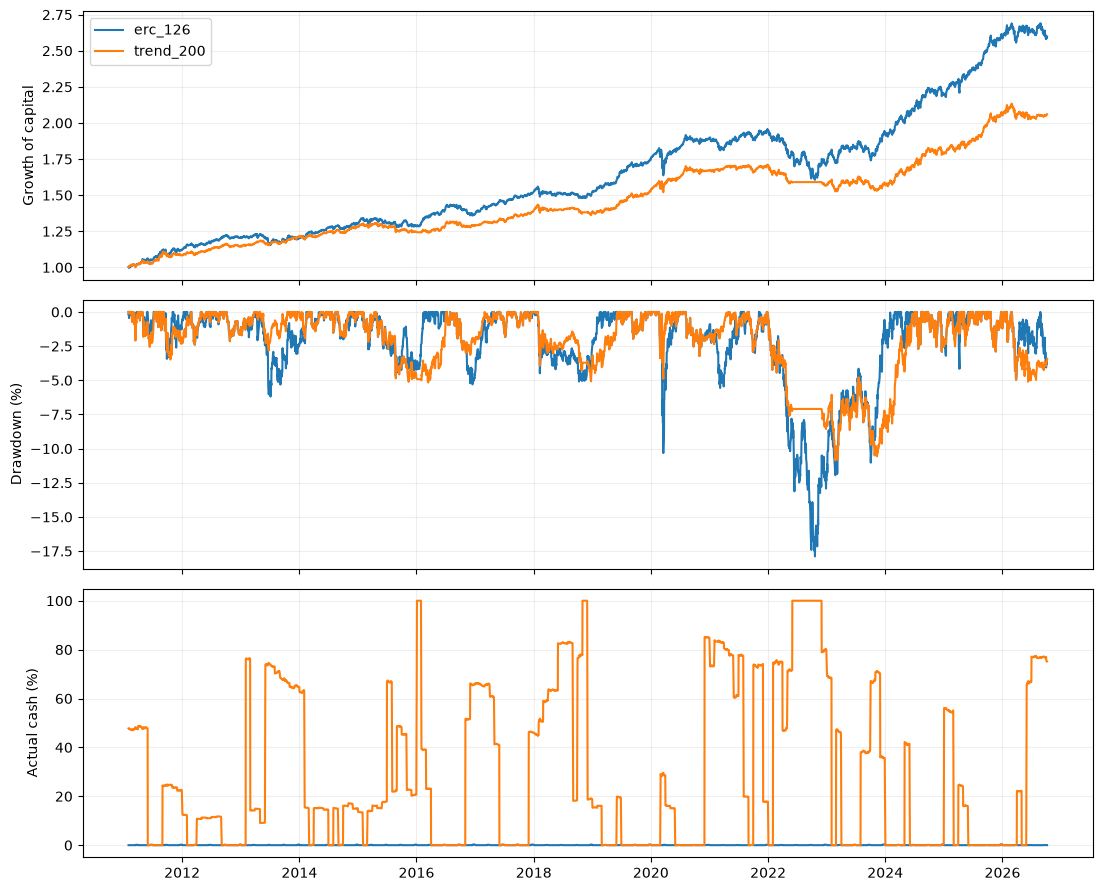

加入趋势后，年化收益相差 **-1.56 个百分点**，最大回撤为 **-10.86%**（基准 **-17.89%**），平均实际现金为 **29.60%**。这些结果只描述当前历史样本，不能据此确定效果来自择时能力还是降低敞口。

In [3]:
schedules={'erc_126':base,'trend_200':trend}
results={name:simulate(trading,s.iloc[0][assets].to_dict(),target_schedule=s)
         for name,s in schedules.items()}
metrics=pd.DataFrame({name:r.metrics() for name,r in results.items()}).T
metrics['mean_daily_cash_weight']=[(r.daily.cash/r.daily.nav).mean() for r in results.values()]
metrics['all_cash_days']=[int((r.daily.cash/r.daily.nav>=1-1e-10).sum()) for r in results.values()]
metrics.to_csv(OUT/'metrics.csv')
display(metrics[['final_nav','cagr','annual_volatility','max_drawdown']].style.format({
    'final_nav':'{:,.2f}','cagr':'{:.2%}','annual_volatility':'{:.2%}','max_drawdown':'{:.2%}'}))
print('上表：期末资产／年化收益／年化波动／最大回撤。')
display(metrics[['fees_paid','trade_days','mean_daily_cash_weight','all_cash_days']].style.format({
    'fees_paid':'{:,.2f}','trade_days':'{:.0f}','mean_daily_cash_weight':'{:.2%}','all_cash_days':'{:.0f}'}))
print('上表：累计费用／交易日数／日均实际现金比例／全现金天数。交易天数较少不保证费用少，还要看每次买卖金额。')
fig,axes=plt.subplots(3,1,figsize=(11,9),sharex=True)
for name,r in results.items():
    nav=r.daily.nav;peak=np.maximum.accumulate(np.r_[r.initial_cash,nav])[1:]
    axes[0].plot(nav.index,nav/r.initial_cash,label=name)
    axes[1].plot(nav.index,(nav/peak-1)*100,label=name)
    axes[2].plot(nav.index,r.daily.cash/nav*100,label=name)
axes[0].set_ylabel('Growth of capital');axes[0].legend()
axes[1].set_ylabel('Drawdown (%)');axes[2].set_ylabel('Actual cash (%)')
fig.tight_layout();fig.savefig(OUT/'comparison.png',dpi=150);plt.show()
a,b=metrics.loc['erc_126'],metrics.loc['trend_200']
display(Markdown(f'加入趋势后，年化收益相差 **{100*(b.cagr-a.cagr):+.2f} 个百分点**，最大回撤为 **{b.max_drawdown:.2%}**（基准 **{a.max_drawdown:.2%}**），平均实际现金为 **{b.mean_daily_cash_weight:.2%}**。这些结果只描述当前历史样本，不能据此确定效果来自择时能力还是降低敞口。'))

## 4. 不只看全区间：逐年结果与时间分段

同一个信号可能在持续下跌中有帮助，在反复震荡或快速反弹中吃亏。下面展示全部年度，而不是只选有利时期。2011 和 2026 是不完整年份，不把它们当作完整年收益。

另将历史按 2020-01-01 切成两段，观察效果是否一致。规则和参数不变，账户连续运行、不重置持仓；各段回撤在边界重新计算。后半段已被之前课程看过，叫**历史分段诊断**，不叫真正样本外。未来验证需要冻结规则、记录当时数据并等待新观察。

In [4]:
daily_returns={name:r.daily.nav.div(r.daily.nav.shift(1).fillna(r.initial_cash))-1
               for name,r in results.items()}
annual=pd.DataFrame({name:(1+ret).groupby(ret.index.year).prod()-1
                     for name,ret in daily_returns.items()})
annual['trend_minus_base_pp']=(annual.trend_200-annual.erc_126)*100
annual.to_csv(OUT/'annual_returns.csv')
display(annual.style.format({'erc_126':'{:.2%}','trend_200':'{:.2%}','trend_minus_base_pp':'{:+.2f}'}))
worst=annual.trend_minus_base_pp.idxmin()
display(Markdown(f'相对基准表现最弱的年度是 **{worst}**：趋势方案 **{annual.loc[worst,"trend_200"]:.2%}**，基准 **{annual.loc[worst,"erc_126"]:.2%}**。这是提示我们调查失败路径的入口，并不自动证明具体因果。'))
rows=[]
for name,r in results.items():
    for label,mask in [('before_2020',r.daily.index<pd.Timestamp('2020-01-01')),
                       ('2020_onward',r.daily.index>=pd.Timestamp('2020-01-01'))]:
        nav=r.daily.nav.loc[mask]
        if len(nav)<2: continue
        pos=r.daily.index.get_loc(nav.index[0])
        initial=r.initial_cash if pos==0 else r.daily.nav.iloc[pos-1]
        origin=nav.index[0] if pos==0 else r.daily.index[pos-1]
        years=(nav.index[-1]-origin).days/365.25
        values=np.r_[initial,nav.to_numpy()]
        rows.append(dict(period=label,policy=name,cagr=(nav.iloc[-1]/initial)**(1/years)-1,
            max_drawdown=(values/np.maximum.accumulate(values)-1).min(),
            mean_cash=(r.daily.cash.loc[mask]/nav).mean()))
segments=pd.DataFrame(rows).set_index(['period','policy'])
display(segments.style.format('{:.2%}'));segments.to_csv(OUT/'historical_segments.csv')

,erc_126,trend_200,trend_minus_base_pp
date,,,
2011,12.32%,8.77%,-3.56
2012,7.35%,5.42%,-1.93
2013,-0.38%,6.07%,+6.45
2014,8.34%,5.12%,-3.21
2015,-1.36%,-2.64%,-1.28
2016,6.61%,3.38%,-3.23
2017,11.12%,7.87%,-3.26
2018,-0.06%,-0.47%,-0.41
2019,14.77%,10.52%,-4.24


相对基准表现最弱的年度是 **2023**：趋势方案 **0.85%**，基准 **12.79%**。这是提示我们调查失败路径的入口，并不自动证明具体因果。

,,cagr,max_drawdown,mean_cash
period,policy,,,
before_2020,erc_126,6.44%,-6.19%,0.02%
2020_onward,erc_126,6.07%,-17.89%,0.02%
before_2020,trend_200,4.86%,-5.16%,26.66%
2020_onward,trend_200,4.53%,-10.86%,33.48%


## 5. 迟滞和反复进出：看清信号真正发生的时间

**迟滞（lag）**：均线由过去价格构成，转弱之后才可能发出退出信号；月度检查又增加等待时间。它不预测顶部、底部，也不等于每日止损。

**反复进出（whipsaw）**：价格在均线附近来回穿越，可能刚卖出又买回，承担成本且错过上涨。

下面固定观察 2020 年 SPY 的月度决定，作为快速变化情景的例子，不用图形代替交易记录。圆点表示“决策日收盘价格”，绿色启用、红色关闭；实际执行在下一个月初观察日。价格曲线每天更新，但本策略只在这些月度点做决定。

,decision_date,execution_date,signal,base_weight,target_weight
324,2020-01-31 00:00:00,2020-02-03 00:00:00,1,32.24%,32.24%
327,2020-02-28 00:00:00,2020-03-02 00:00:00,0,28.97%,0.00%
330,2020-03-31 00:00:00,2020-04-01 00:00:00,0,16.30%,0.00%
333,2020-04-30 00:00:00,2020-05-01 00:00:00,0,15.17%,0.00%
336,2020-05-29 00:00:00,2020-06-01 00:00:00,1,14.86%,14.86%
339,2020-06-30 00:00:00,2020-07-01 00:00:00,1,14.49%,14.49%
342,2020-07-31 00:00:00,2020-08-03 00:00:00,1,14.16%,14.16%
345,2020-08-31 00:00:00,2020-09-01 00:00:00,1,14.39%,14.39%
348,2020-09-30 00:00:00,2020-10-01 00:00:00,1,12.90%,12.90%
351,2020-10-30 00:00:00,2020-11-02 00:00:00,1,14.26%,14.26%


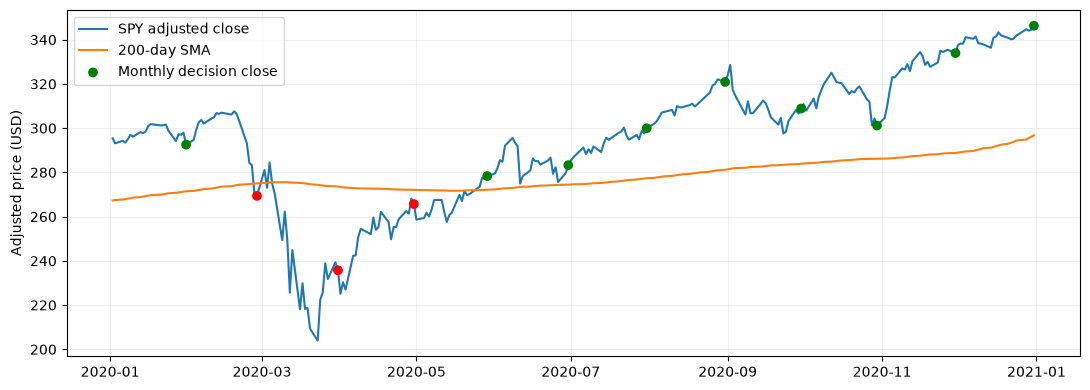

信号0只表示暂不持有，不预测必然下跌；信号1也不代表未来上涨概率为100%。


In [5]:
event=audit[(audit.asset=='SPY') & (audit.decision_date.dt.year==2020)].copy()
display(event[['decision_date','execution_date','signal','base_weight','target_weight']].style.format({
    'base_weight':'{:.2%}','target_weight':'{:.2%}'}))
ma=prices.SPY.rolling(200,min_periods=200).mean()
period=prices.index.year==2020
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(prices.index[period],prices.SPY.loc[period],label='SPY adjusted close')
ax.plot(ma.index[period],ma.loc[period],label='200-day SMA')
ax.scatter(event.decision_date,event.adjusted_close,c=event.signal.map({1:'green',0:'red'}),
           label='Monthly decision close',zorder=3)
ax.set_ylabel('Adjusted price (USD)');ax.legend();fig.tight_layout()
fig.savefig(OUT/'spy_2020_decisions.png',dpi=150);plt.show()
print('信号0只表示暂不持有，不预测必然下跌；信号1也不代表未来上涨概率为100%。')

## 6. 成本敏感性与验证边界

固定同一组目标，分别假设单边 0、5、20 bps，检查交易摩擦影响。0 bps 只用于对照，不代表真实可以免费成交；20 bps 也不是市场冲击模型或所有情况下的成本上限。账户规模和持仓路径会随费用变化，因此最终差异不仅是简单减去一笔费用。

本课没有搜索窗口，也没有训练模型；这仍不代表策略已经有效。历史分段、未来价格扰动测试、对账分别检查不同问题：稳定性、时序、记账。它们都不能代替前瞻验证。

In [6]:
cost_rows=[]
for bps in [0,5,20]:
    for name,s in schedules.items():
        r=results[name] if bps==5 else simulate(trading,s.iloc[0][assets].to_dict(),
            target_schedule=s,cost_bps=bps)
        reconcile(r)
        m=r.metrics()
        cost_rows.append(dict(cost_bps=bps,policy=name,cagr=m.cagr,max_drawdown=m.max_drawdown,fees_paid=m.fees_paid))
costs=pd.DataFrame(cost_rows).set_index(['cost_bps','policy'])
display(costs.style.format({'cagr':'{:.2%}','max_drawdown':'{:.2%}','fees_paid':'{:,.2f}'}))
costs.to_csv(OUT/'cost_sensitivity.csv')
checks=pd.DataFrame({name:reconcile(r) for name,r in results.items()}).T
assert checks.to_numpy().max()<1e-6
for name,r in results.items():
    r.daily.to_csv(OUT/(name+'_daily.csv'))
    r.trades.to_csv(OUT/(name+'_trades.csv'),index=False)
    r.distributions.to_csv(OUT/(name+'_distributions.csv'),index=False)
# When previous lesson outputs exist, assert unchanged common-period baseline.
previous_path=ROOT/'reports'/('05_'+SNAPSHOT)/'metrics.csv'
if previous_path.exists():
    previous=pd.read_csv(previous_path,index_col=0).loc['erc_126']
    fields=['final_nav','cagr','annual_volatility','max_drawdown','fees_paid']
    np.testing.assert_allclose(metrics.loc['erc_126',fields].astype(float),previous[fields],rtol=1e-10,atol=1e-7)
    print('第六课 ERC 基准与第五课完全一致。')
settings=dict(snapshot=SNAPSHOT,start=str(START.date()),end=str(prices.index[-1].date()),
    risk_lookback=126,trend_price_observations=200,rule='prior adjusted close > SMA including that close',
    cash_yield=0,renormalize=False,cost_bps=5,source_manifest=manifest,
    interpretation='historical exploratory comparison, not untouched out of sample',
    code_sha256={p:hashlib.sha256((ROOT/p).read_bytes()).hexdigest() for p in
        ['src/signals.py','src/risk_models.py','src/portfolio.py','notebooks/build_06.py','docs/06_research_design.md']})
(OUT/'run_manifest.json').write_text(json.dumps(settings,indent=2),encoding='utf-8')
print('账本核对通过，最大误差：',checks.to_numpy().max())

第六课 ERC 基准与第五课完全一致。
账本核对通过，最大误差： 3.3760443329811096e-09


## 7. 本课在第二阶段的作用与后续路线

本课的交付是一个**可以追踪到数据和交易的信号实验**。每个决策都能查到价格、均线、0/1信号、基础权重、实际目标和现金比例。这个接口为未来的其他规则、统计模型和机器学习保留位置。

第二阶段接下来研究：① 与相近风险敞口的简单对照比较，避免把少持仓当成择时能力；② 现金收益、成本、失败年份与稳健性；③ 冻结规则和样本划分，建立真正前瞻的模拟记录。复杂模型应在这些验证之后加入。

**仍未解决**：收益归因、现金利息、真实分红支付日、数据修订、开盘滑点、税务与结算、独立样本外有效性。月度策略可能错过突发下跌与快速反弹；不承诺防御所有危机。信号使用当前下载的调整后历史，不是历史时点原始可得数据的完整复刻。

### 自测与参考答案

1. 基础权重 30/50/20，信号 1/0/1，目标是什么？——30/0/20，现金50%，不重新归一化。
2. 周二跌破均线，周三一定卖出吗？——不，本课仅月度决策，随后月初开盘执行。
3. 相等于均线怎么处理？——信号0，这是明确的边界规则，不意味着经济上存在神奇分界。
4. 回撤下降能否证明会择时？——不能，也可能因为持有更多现金，需要对照与归因。
5. 2020年后表现不错是否就算样本外成功？——不能，这段历史早已被观察；没有调参也不能让已知数据变回未知。

学完后，你应能从“这个策略赚了多少”进一步追问：“它何时改变敞口、依据是什么、代价是什么，以及证据是否足够？”